# Coordinated Wildfire Drone Fleet Monitoring with Reinforcement Learning

**COMP6008 Reinforcement Learning, Group 7**

| Section | Content |
|---|---|
| 0 | Setup and how to reproduce |
| 1 | Problem: importance, difficulty, why RL |
| 2 | MDP: state, action, transition model $p(s'\mid s,a)$, reward |
| 3 | The simulator in code |
| 4 | Conventional baselines |
| 5 | RL agents: DQN, REINFORCE, A2C (pseudocode linked to code) |
| 6 | Modification: feasible-action masking |
| 7 | Training and learning curves |
| 8 | Hyperparameter tuning |
| 9 | Final test on unseen scenarios |
| 10 | Sensitivity: battery, charging, fire spread |
| 11 | Critical review |

Each section starts with an author line, as the unit guidelines require. Fill in the names.

## 0. Setup and how to reproduce
**Author: _(name)_**

**Local run.** From the repository root:

```bash
python -m venv .venv && source .venv/bin/activate     # Windows: .venv\Scripts\activate
python -m pip install -r requirements.txt
python -m pip install -e .
jupyter notebook Wildfire_Drone_Fleet.ipynb
```

**Google Colab.** Upload the repository (or clone it), then run the first cell, which installs the package.

With `RUN_EXPERIMENTS=False`, results are loaded from `docs/experiments/final-2026-10-05/`, the archived study. With `RUN_EXPERIMENTS=True`, each section reads its new
outputs under `runs/masked-study` or `runs/final`. Existing completed fits must
match the requested configuration; use a new output folder for different settings. Re-running the training is optional and controlled by
`RUN_EXPERIMENTS` (about 1.5 hours on a 4-core CPU):

```bash
python scripts/run_masked_study.py --episodes 300 --out runs/masked-study
python scripts/run_final_study.py tune --seeds 0 --episodes 200
python scripts/run_final_study.py test
python scripts/run_final_study.py sensitivity --seeds 0 --algorithm dqn
```

In [1]:
import subprocess, sys
from pathlib import Path

REPO = Path.cwd()
if not (REPO / 'src' / 'wild_drone').exists():   # opened from notebooks/ or Colab
    REPO = REPO.parent if (REPO.parent / 'src' / 'wild_drone').exists() else REPO
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
sys.path.insert(0, str(REPO / 'src'))

import json, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RESULTS = REPO / 'docs' / 'experiments' / 'final-2026-10-05'
RUN_EXPERIMENTS = False          # set True to retrain everything from scratch
MASKED_OUT = REPO / 'runs' / 'masked-study'
FINAL_OUT = REPO / 'runs' / 'final'
MASKED_RESULTS = MASKED_OUT if RUN_EXPERIMENTS else RESULTS / 'masked-study'
TUNE_RESULTS = FINAL_OUT / 'tune' if RUN_EXPERIMENTS else RESULTS
TEST_RESULTS = FINAL_OUT / 'test' if RUN_EXPERIMENTS else RESULTS
SENSITIVITY_RESULTS = FINAL_OUT / 'sensitivity' if RUN_EXPERIMENTS else RESULTS
pd.set_option('display.precision', 3)
print('repository:', REPO)

repository: /tmp/claude-0/repo


## 1. The problem
**Author: _(name)_**

**What has to be solved.** Emergency responders need repeated, close-range inspection of
active fire fronts and high-priority areas (towns, roads, infrastructure). A fleet of three
battery-limited drones shares this workload. Each drone must come back to a single base
charger before its battery runs out, so the fleet has to decide *where* each drone inspects
and *when* it returns, while the fire spreads and the wind changes.

**Why it matters.** Information that is out of date can lead to poor evacuation and
suppression decisions. Inspection timeliness of the most dangerous areas is therefore the
quantity of interest, not one-off coverage. UAV fire monitoring is an active research area
[Viseras et al. 2021; Julian & Kochenderfer 2019].

**Why it is hard.**
- *Combinatorial joint action:* 5 commands per drone gives $5^3 = 125$ joint actions per step.
- *Long-horizon resource trade-off:* sending every drone to the hottest area now can leave
  the whole fleet recharging together later, and one charger serves one drone at a time.
- *Delayed, catastrophic penalties:* a drone that strays too far is lost many steps after
  the decision that caused it.
- *Stochastic dynamics:* fire spread and wind are random, so plans must be revised.

**Why RL.** The problem is a sequential decision under uncertainty with a clear numerical
objective. A simulator is available, so an agent can learn by trial and error, and a
learned policy can react in milliseconds where a planner must search. We do **not** assume
RL wins: we compare it against greedy and rolling-horizon planning.

## 2. Markov decision process
**Author: _(name)_**

The controller observes the complete simulator state (fully observable MDP). One central
policy controls all three drones.

### 2.1 State $s_t$

| Symbol | Meaning | Shape / range |
|---|---|---|
| $B_t$ | burning cells | $\{0,1\}^{n\times n}$ |
| $F_t$ | remaining fuel | $\{0,\dots,F_{max}\}^{n\times n}$ |
| $T$ | terrain susceptibility (static) | $[0.4,1]^{n\times n}$ |
| $P$ | priority (static, 1 or 3) | $\{1,3\}^{n\times n}$ |
| $A_t$ | inspection age of every cell | $\{0,\dots,A_{max}\}^{n\times n}$ |
| $x^i_t, b^i_t, \ell^i_t$ | position, battery, lost flag of drone $i=1,2,3$ | grid cell, $[0,b_{max}]$, $\{0,1\}$ |
| $w_t$ | wind direction (none, N, S, W, E) | $\{0,\dots,4\}$ |
| $o_t$ | which drone holds the charger (or none) | $\{-1,0,1,2\}$ |
| $\tau_t$ | time remaining | $1 - t/H$ |

The observation is this state, normalised to $[0,1]$: five $n\times n$ maps, a $3\times4$
drone table and a 12-value global vector. Nothing is hidden, so no observation history is needed.

### 2.2 Action $a_t$

$a_t = (u^1_t, u^2_t, u^3_t)$ with $u^i \in \{\text{stay}, N, S, W, E\}$, encoded as one
integer $a = 25u^1 + 5u^2 + u^3 \in \{0,\dots,124\}$. Inspection is automatic within the
sensor radius $r$. Staying at the base requests charging.

### 2.3 Transition model $p(s_{t+1}\mid s_t,a_t)$

The step is applied in this order (`environment.py`, `step()` lines 198-235).

1. **Movement.** Proposed cell $y^i = x^i + \delta(u^i)$. Off-grid moves and moves into the
   same non-base cell or a direct swap are rejected ($y^i \leftarrow x^i$); a rejected move
   counts as a collision attempt $C_t$.
2. **Charging.** Among drones grounded at base with $b^i<b_{max}$, the current owner keeps the
   charger, otherwise the lowest battery takes it: $b^o_{t+1} = \min(b_{max}, b^o_t + \rho)$.
3. **Energy and loss.** $b^i_{t+1} = \max(0,\, b^i_t - c(u^i))$ with $c=c_{move}$ for a move,
   $c_{hover}$ for stay, and $0$ when waiting on the ground at base.
   $\ell^i_{t+1} = \ell^i_t \lor (b^i_{t+1} \le 0 \land x^i_{t+1} \neq \text{base})$.
4. **Inspection.** With footprint $\mathcal{S}_t$ (union of live drones' $(2r+1)^2$ squares):
   $A_{t+1}(c) = 0$ if $c\in\mathcal{S}_t$, otherwise $\min(A_t(c)+1, A_{max})$.
5. **Fire spread (stochastic).** A non-burning cell $c$ with fuel ignites with probability
   $$p_{ign}(c) = 1 - \prod_{n \in \mathcal{N}(c),\, B_t(n)=1} \bigl(1 - p_{s}\,\kappa_{w}(n\!\to\! c)\,T(c)\bigr),$$
   where $\kappa_w = $ wind multiplier if the spread direction matches the wind, else 1.
   Burning cells lose one unit of fuel: $F_{t+1} = F_t - B_t$, and
   $B_{t+1} = (B_t \land F_{t+1}>0) \lor \text{ignite}$.
6. **Wind (stochastic).** $w_{t+1} \sim \text{Uniform}\{0..4\}$ with probability $p_w$, else $w_{t+1}=w_t$.
7. **Termination.** The episode ends at $t = H$ or when all three drones are lost.

Steps 1-4 are deterministic given $(s_t,a_t)$; all randomness enters in steps 5-6, through
the environment's seeded generator. Each scenario seed also randomises fuel, terrain,
the three priority zones and the initial ignitions.

### 2.4 Reward $r_t$

Hazard weight of a cell: $W_t(c) = P(c)\,(1 + 2B_t(c) + \text{front}_t(c))$, where a front
cell is unburnt, has fuel and touches fire. With inspection deadline $D$:

$$r_t = \underbrace{\alpha\,\frac{\sum_{c\in\mathcal{S}_t} W_t(c)\min(A_t(c)/D,1)}{\sum_c W_t(c)}}_{\text{freshness gain}}
- \underbrace{\beta\,\frac{\sum_c W_t(c)\,\mathbb{1}[A_t(c)>D]}{\sum_c W_t(c)}}_{\text{overdue}}
- \eta\frac{E_t}{b_{max}} - \kappa\, C_t - \lambda\, L_t
- \mathbb{1}[\text{all lost}]\,\beta\,(H-t-1)$$

| Term | Weight | Why it matches the goal |
|---|---|---|
| Freshness gain | $\alpha=1$ | Rewards inspecting stale, high-hazard cells: this *is* the objective. Bounded by 1 per step |
| Overdue | $\beta=0.1$ | Dense shaping signal every step; pushes the fleet to keep all priority areas inside the deadline |
| Energy | $\eta=0.02$ | Small cost so that useless movement is avoided |
| Collision attempts | $\kappa=0.2$ | Discourages conflicting commands |
| Drone loss | $\lambda=5$ | Large penalty for running a battery flat away from base |
| Fleet failure | $\beta(H-t-1)$ | Charges the overdue cost of the unserved rest of the mission, so ending early never pays |

The freshness and overdue terms are dense, so the agent receives feedback at every step
rather than only at the end of a mission, which speeds up learning.

## 3. The simulator in code
**Author: _(name)_**

Development configuration (all experiments): 20×20 grid, horizon $H=160$, battery 80,
move cost 1, hover cost 0.25, recharge 5 per step, sensor radius 1, deadline 25.
The Gymnasium API checker confirms the environment follows `gymnasium.Env`.

In [2]:
from wild_drone.config import EnvConfig
from wild_drone.environment import WildfireFleetEnv
from gymnasium.utils.env_checker import check_env

raw = json.loads((REPO / 'configs' / 'development.json').read_text())
CONFIG = EnvConfig(**raw['environment'])
env = WildfireFleetEnv(CONFIG, render_mode='rgb_array')
check_env(env.unwrapped, skip_render_check=True)
obs, info = env.reset(seed=5000)
print({k: v.shape for k, v in obs.items()}, '| actions:', env.action_space.n)
print(pd.Series(CONFIG.to_dict()).to_string())

{'maps': (5, 20, 20), 'drones': (3, 4), 'globals': (12,)} | actions: 125
grid_size                   20.00
horizon                    160.00
battery_capacity            80.00
move_cost                    1.00
hover_cost                   0.25
recharge_rate                5.00
sensor_radius                1.00
inspection_deadline         25.00
max_fuel                   100.00
initial_fires                3.00
spread_probability           0.04
wind_multiplier              2.00
wind_change_probability      0.06
freshness_reward             1.00
overdue_penalty              0.10
energy_penalty               0.02
collision_penalty            0.20
loss_penalty                 5.00


In [3]:
# The transition function (steps 1-7 of section 2.3).
print(inspect.getsource(WildfireFleetEnv.step))
print(inspect.getsource(WildfireFleetEnv._evolve_fire))

    def step(self, action):
        if self._done:
            raise RuntimeError('call reset() before stepping a finished environment')
        commands = decode_action(action)
        previous = self.positions.copy()
        collisions = self._resolve_moves(commands)
        energy, losses, returns, completions = self._energy_and_charging(commands, previous)
        self.ages[:] = np.minimum(self.ages+1, self.age_limit)
        weights = self.priority_weights()
        mask = self._inspection_mask()
        gain = float((weights[mask]*np.minimum(
            self.ages[mask]/self.config.inspection_deadline, 1)).sum()/weights.sum())
        self.ages[mask] = 0
        inspection_metrics = self._metrics(weights)
        c = self.config
        components = {
            'freshness_gain': c.freshness_reward*gain,
            'overdue': -c.overdue_penalty*inspection_metrics['overdue_fraction'],
            'energy': -c.energy_penalty*energy/c.battery_capacity,
            'collisions': -c

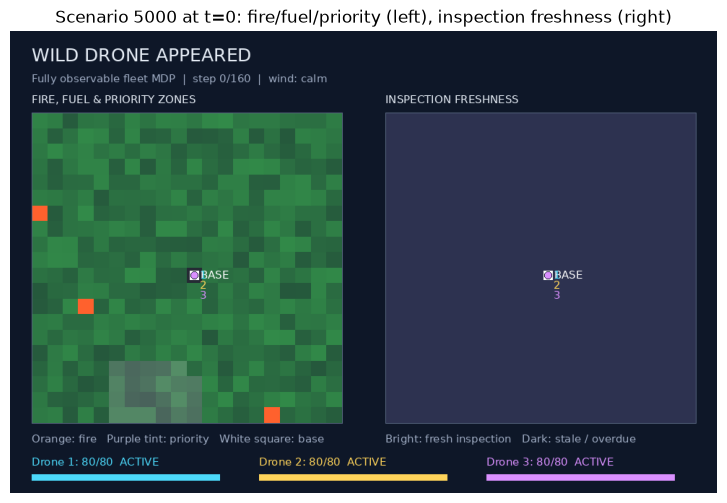

In [4]:
plt.figure(figsize=(12, 6))
plt.imshow(env.render()); plt.axis('off')
plt.title('Scenario 5000 at t=0: fire/fuel/priority (left), inspection freshness (right)')
plt.show()

## 4. Conventional baselines
**Author: _(name)_**

All controllers see the same state and obey the same physics.

| Controller | Idea |
|---|---|
| Random | Uniform over the 125 joint actions (sanity check) |
| All stay | Every drone waits at base: the "do nothing" reference |
| Masked random | Uniform over the *feasible* actions of section 6 |
| Sweep | Each drone patrols its own third of the map in a serpentine, returning when low |
| Greedy | Picks the feasible joint action with the largest immediate priority-weighted freshness gain |
| Planner | Rolling-horizon stochastic shooting: simulates 8 candidate first actions for 3 steps (2 samples each), replans every step |

In [5]:
from wild_drone.baselines import candidate_actions, GreedyPolicy
print(inspect.getsource(candidate_actions))
print(inspect.getsource(GreedyPolicy))

def candidate_actions(env):
    """Feasible baseline proposals. This is NOT a shield applied to RL policies."""
    c = env.config
    proposed = env.positions[None, :, :] + MOVES[COMMANDS]
    valid = ~np.any((proposed < 0) | (proposed >= c.grid_size), axis=(1, 2))
    distances = np.abs(proposed-env.base).sum(axis=2)
    current_distances = np.abs(env.positions-env.base).sum(axis=1)
    for i in range(3):
        if env.lost[i]:
            valid &= COMMANDS[:, i] == 0
            continue
        if current_distances[i] == 0 and env.batteries[i] < c.battery_capacity:
            valid &= COMMANDS[:, i] == 0
            continue
        costs = np.where(COMMANDS[:, i] == 0, c.hover_cost, c.move_cost)
        if current_distances[i] == 0:
            costs[COMMANDS[:, i] == 0] = 0
        low_battery = env.batteries[i] <= current_distances[i]*c.move_cost + 3*c.move_cost
        if low_battery and current_distances[i] > 0:
            valid &= distances[:, i] < current_distances[i]
   

## 5. RL agents
**Author: _(name)_**

All three agents are written from scratch in PyTorch and share one network
(`learning.py` `FleetNetwork`, line 171): a two-layer CNN over 9 input maps (the 5 state
maps plus one-hot positions of the 3 drones and the base), concatenated with the 24-value
drone/global vector, a 128-unit hidden layer and a 125-way output head. A2C and REINFORCE
add a one-unit value head (critic / baseline).

| Agent | Family | Why it suits this problem |
|---|---|---|
| DQN | Value-based, off-policy TD | Discrete action set; replay reuses scarce successful return-and-recharge transitions [Mnih et al. 2015] |
| REINFORCE | Monte Carlo policy gradient | Learns directly from complete mission returns; unbiased, handles the delayed loss penalty without bootstrapping [Williams 1992] |
| A2C | Actor-critic | A learned value function lowers the gradient variance of REINFORCE and allows updates every 16 steps [Mnih et al. 2016] |

The masked training loop is in `src/wild_drone/masked_learning.py` (`train_masked`).
The line numbers below refer to that file unless marked `learning.py`.

### 5.1 Deep Q-Network (DQN)

```
Initialise Q-network θ, target network θ⁻ ← θ, replay buffer D (size 2000)
for each episode:
    observe s, feasible set M(s)
    for each step:
 1      ε ← linear decay from 1.0 to 0.05 over 10,000 steps
 2      a ← random action in M(s) with prob. ε, else argmax_{a∈M(s)} Q(s,a;θ)
 3      execute a, observe r, s', done, M(s')
 4      store (s, a, r, s', done, M(s')) in D
 5      sample a minibatch of 32 transitions from D
 6      y ← r + γ (1−done) max_{a'∈M(s')} Q(s',a';θ⁻)
 7      minimise Huber(Q(s,a;θ) − y), clip gradient norm to 0.5, Adam step
 8      every 100 steps: θ⁻ ← θ
```

| Step | Code |
|---|---|
| 1 | `masked_learning.py` line 200 |
| 2 | lines 202-207 (`apply_mask`, line 92) |
| 3 | line 220 (`env.step`) |
| 4 | line 227 |
| 5 | line 229 |
| 6 | lines 236-239: `td_targets` (`learning.py` line 120) with `masked_max` (line 98) |
| 7 | line 240, `optimise` line 177 |
| 8 | lines 241-242 |

In [6]:
from wild_drone import learning, masked_learning
for fn in (learning.td_targets, masked_learning.masked_max, masked_learning.apply_mask):
    print(inspect.getsource(fn))

def td_targets(rewards, terminals, next_values, gamma):
    return rewards + gamma*(~terminals).float()*next_values

def masked_max(q_values, masks):
    """Maximum Q over feasible next actions only (DQN target)."""
    return apply_mask(q_values, masks).max(dim=1).values

def apply_mask(logits, mask):
    """Give infeasible actions the lowest finite logit: zero probability, finite entropy."""
    mask = torch.as_tensor(mask, device=logits.device).reshape(logits.shape)
    return logits.masked_fill(~mask, torch.finfo(logits.dtype).min)



### 5.2 REINFORCE with a learned baseline

```
Initialise policy π(a|s;θ) and baseline V(s;θ) (shared encoder)
for each episode:
 1   generate a whole mission s₀,a₀,r₀,…,s_{T−1},a_{T−1},r_{T−1} with a ~ π(·|s) restricted to M(s)
 2   for t = 0..T−1:  G_t ← Σ_{k≥t} γ^{k−t} r_k
 3   δ_t ← G_t − V(s_t)                      (V is not used for bootstrapping)
 4   L_actor  ← −(1/H) Σ_t γ^t δ_t log π(a_t|s_t)
 5   L_critic ← mean_t (G_t − V(s_t))²
 6   L ← L_actor + 0.5 L_critic − β_H · mean_t entropy(π(·|s_t))
 7   gradient step on L (clip norm 0.5, Adam)
```

| Step | Code |
|---|---|
| 1 | lines 209-217 (`Categorical(logits=apply_mask(...))`) |
| 2 | `learning.py` `discounted_returns`, line 111 |
| 3-5 | `learning.py` `monte_carlo_terms`, line 140, and `discounted_policy_loss`, line 132 |
| 6-7 | `masked_learning.py` lines 258-261 |

In [7]:
for fn in (learning.discounted_returns, learning.discounted_policy_loss, learning.monte_carlo_terms):
    print(inspect.getsource(fn))

def discounted_returns(rewards, gamma, bootstrap=0.0):
    result = np.empty(len(rewards), dtype=np.float32)
    running = float(bootstrap)
    for i in range(len(rewards)-1, -1, -1):
        running = rewards[i] + gamma*running
        result[i] = running
    return result

def discounted_policy_loss(log_probs, advantages, gamma, *, start_step, normalizer):
    """Absolute-time weighting; fixed normalisation cannot favour short failures."""
    times = torch.arange(start_step, start_step+len(log_probs), dtype=log_probs.dtype,
                         device=log_probs.device)
    weights = torch.pow(torch.full_like(times, gamma), times)
    return -(log_probs*advantages*weights).sum()/normalizer

def monte_carlo_terms(log_probs, rewards, gamma, *, horizon, values=None):
    """REINFORCE terms: full reward-to-go, no value bootstrap or return centering."""
    returns = torch.from_numpy(discounted_returns(rewards, gamma)).to(log_probs.device)
    advantage = returns if values is None els

### 5.3 Advantage actor-critic (A2C, synchronous n-step)

```
Initialise actor π(a|s;θ) and critic V(s;θ) (shared encoder)
for each episode:
    for each step:
 1      sample a ~ π(·|s) restricted to M(s), execute, store (log π, V(s), entropy, r)
 2      if n = 16 steps collected or the episode ended:
 3          bootstrap B ← 0 if terminal else V(s_{t+1})
 4          R_k ← r_k + γ R_{k+1}, with R_n = B            (n-step returns)
 5          A_k ← R_k − V(s_k)                              (advantage)
 6          L ← −(1/n) Σ_k γ^{t_k} A_k log π(a_k|s_k) + 0.5 mean_k (R_k − V(s_k))² − β_H · mean entropy
 7          gradient step on L, clear the rollout
```

| Step | Code |
|---|---|
| 1 | lines 209-217 |
| 2 | line 243 |
| 3 | lines 244-246 |
| 4 | line 247 (`discounted_returns` with bootstrap) |
| 5-6 | lines 249-254 |
| 7 | lines 253-255 |

## 6. Modification: feasible-action masking
**Author: _(name)_**

**Observed failure.** Our first versions (`learning.py`, no mask) trained DQN, REINFORCE
and A2C for 1,000 episodes on three seeds. None learned the task: every learned policy
scored worse than simply keeping all drones at base, and most lost the fleet (see
`docs/colab1000-results.md`). Uniform random play loses all three drones in every mission,
so early experience almost never contains a successful "return, wait, recharge"
sequence for the agents to learn from.

**Fix.** We restrict every learner to the same feasible-action set $M(s)$ the conventional
baselines already use (`baselines.candidate_actions`). An action is feasible when every
drone stays on the grid, no two drones collide, a drone at base that is not full keeps
charging, and every drone keeps enough battery to get home
($b - c(u) \ge c_{move}\cdot(	ext{dist}(y,	ext{base})+1)$; with a low battery it must
move towards base). Infeasible actions get probability zero (actors) or are excluded from
the argmax and from the TD target (DQN). This is a *shield* in the sense of Alshiekh et al. (2018).

The mask is a deterministic function of the fully observed state, so the problem is still
an MDP and the reward and dynamics are unchanged. The learner still has to choose *which*
feasible action is best: masked random scores far below greedy.

In [8]:
print(inspect.getsource(masked_learning.action_mask))
env.reset(seed=5000)
print('feasible joint actions at t=0:', masked_learning.action_mask(env).sum(), 'of 125')

def action_mask(env):
    """Boolean (125,) mask of joint actions the baselines' proposal rule allows.

    The rule checks battery and collisions jointly. When low-battery drones' only base-ward
    cells collide, no joint action passes and it falls back to all-stay, so the drones hover
    until a battery empties (observed with a learned policy). In that case only, use
    `emergency_return_mask` instead.
    """
    mask = np.zeros(125, dtype=bool)
    mask[candidate_actions(env)[0]] = True
    away = ~env.lost & np.any(env.positions != env.base, axis=1)
    distances = np.abs(env.positions-env.base).sum(axis=1)
    low = away & (env.batteries <= (distances+3)*env.config.move_cost)
    if mask.sum() == 1 and mask[0] and low.any():
        return emergency_return_mask(env)
    return mask

feasible joint actions at t=0: 73 of 125


## 7. Training and learning curves
**Author: _(name)_**

Three independent training seeds per agent, 300 episodes each, training scenarios 0-299,
validation scenarios 5000-5004 every 25 episodes. Curves show the per-episode training
return; the shaded band is the spread across seeds.

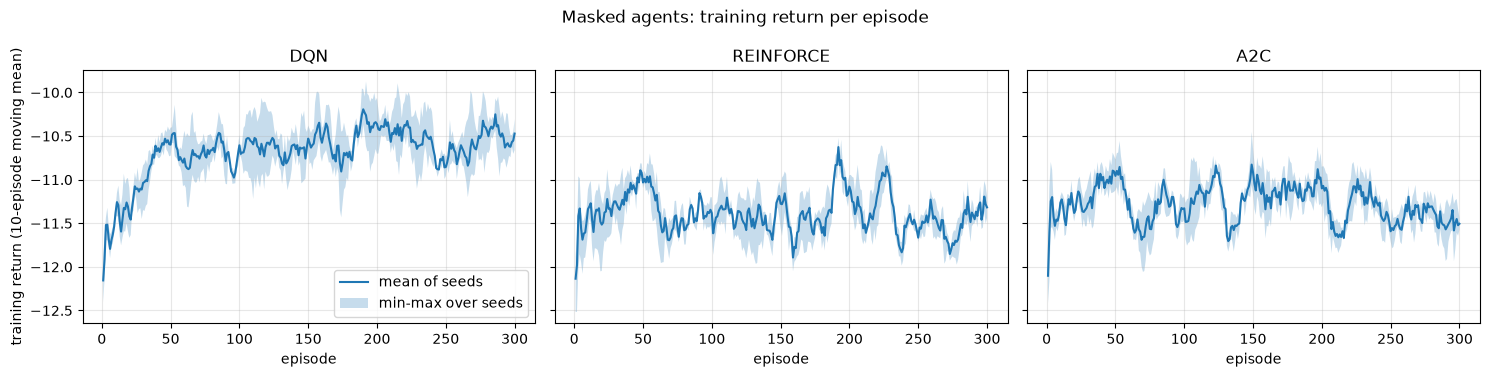

In [9]:
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, 'scripts/run_masked_study.py', '--episodes', '300',
                    '--out', str(MASKED_OUT)], cwd=REPO, check=True)

def learning_curves(folder, title, window=10):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, algorithm in zip(axes, ['dqn', 'reinforce', 'a2c']):
        runs = sorted((folder / algorithm).glob('seed-*/training.csv'))
        curves = np.array([pd.read_csv(p)['return'].rolling(window, min_periods=1).mean()
                           for p in runs])
        x = np.arange(1, curves.shape[1] + 1)
        ax.plot(x, curves.mean(0), label='mean of seeds')
        ax.fill_between(x, curves.min(0), curves.max(0), alpha=0.25, label='min-max over seeds')
        ax.set_title(algorithm.upper()); ax.set_xlabel('episode'); ax.grid(alpha=0.3)
    axes[0].set_ylabel(f'training return ({window}-episode moving mean)')
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

learning_curves(MASKED_RESULTS, 'Masked agents: training return per episode')

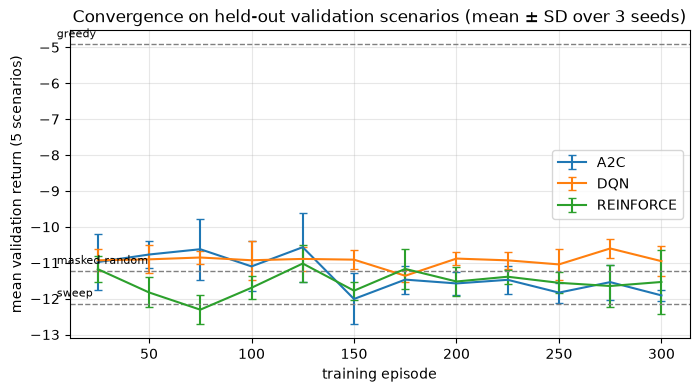

In [10]:
validation = pd.concat([pd.read_csv(p).assign(algorithm=p.parts[-3], seed=p.parts[-2])
                        for p in MASKED_RESULTS.glob('*/seed-*/validation.csv')])
curve = validation.groupby(['algorithm', 'episode', 'seed'])['return'].mean().reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for algorithm, group in curve.groupby('algorithm'):
    stats = group.groupby('episode')['return'].agg(['mean', 'std'])
    ax.errorbar(stats.index, stats['mean'], yerr=stats['std'], capsize=3, label=algorithm.upper())
if RUN_EXPERIMENTS:
    baseline = pd.read_csv(MASKED_RESULTS / 'comparison.csv')
    references = baseline[baseline['training_seed'].isna()].groupby('policy')['return'].mean()
else:
    references = json.loads((RESULTS / 'validation-references.json').read_text())
for name, value in references.items():
    ax.axhline(value, ls='--', lw=1, color='grey'); ax.text(5, value + 0.2, name, fontsize=8)
ax.set_xlabel('training episode'); ax.set_ylabel('mean validation return (5 scenarios)')
ax.set_title('Convergence on held-out validation scenarios (mean ± SD over 3 seeds)')
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 8. Hyperparameter tuning
**Author: _(name)_**

One factor at a time around the defaults, training seed 0, 200 episodes, scored by the
mean return on the five **validation** scenarios at the final episode. Test scenarios are
never used for tuning. Learning rate is tuned for all three agents, entropy weight for the
two policy-gradient agents, and rollout length $n$ for A2C.

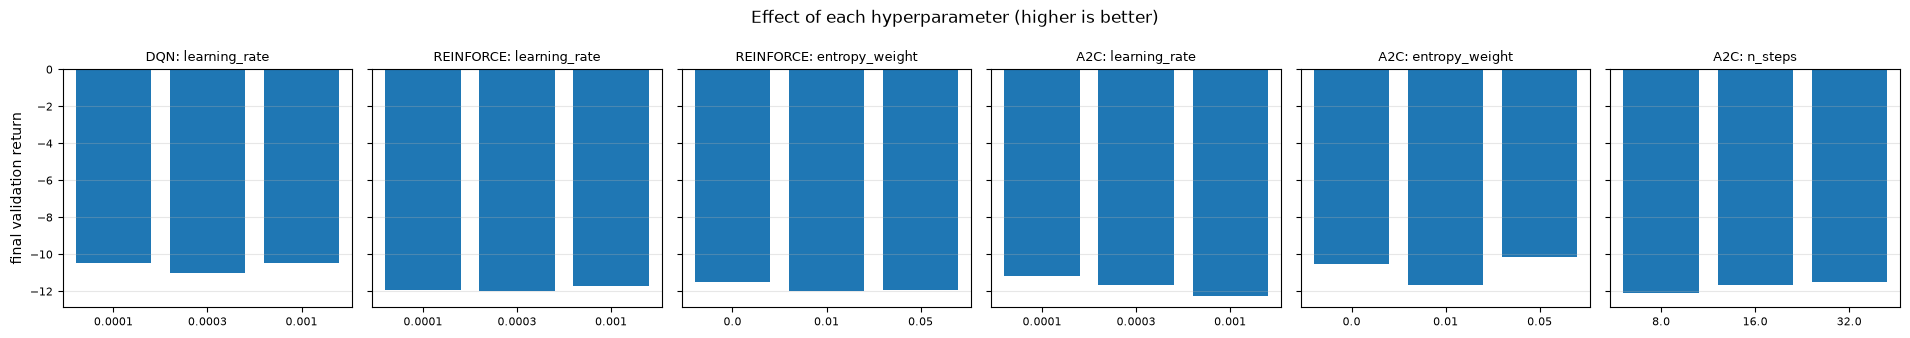

best_validation_return  \
algorithm parameter      value                               
a2c       entropy_weight 0.000e+00                 -10.515   
                         1.000e-02                 -10.390   
                         5.000e-02                 -10.139   
          learning_rate  1.000e-04                 -10.868   
                         3.000e-04                 -10.390   
                         1.000e-03                 -10.424   
          n_steps        8.000e+00                 -10.082   
                         1.600e+01                 -10.390   
                         3.200e+01                 -10.731   
dqn       learning_rate  1.000e-04                 -10.496   
                         3.000e-04                 -10.437   
                         1.000e-03                 -10.236   
reinforce entropy_weight 0.000e+00                 -10.669   
                         1.000e-02                 -11.504   
                         5.000e-02                 -11.154   
          learning_rate  1.000e-04                 -11.393   
                         3.000e-04                 -11.504   
                         1.000e-03                 -11.108   

                                    final_validation_losses  \
algorithm parameter      value                                
a2c       entropy_weight 0.000e+00                      0.0   
                         1.000e-02                      0.0   
                         5.000e-02                      0.0   
          learning_rate  1.000e-04                      0.0   
                         3.000e-04                      0.0   
                         1.000e-03                      0.0   
          n_steps        8.000e+00                      0.0   
                         1.600e+01                      0.0   
                         3.200e+01                      0.0   
dqn       learning_rate  1.000e-04                      0.0   
                         3.000e-04                      0.0   
                         1.000e-03                      0.0   
reinforce entropy_weight 0.000e+00                      0.0   
                         1.000e-02                      0.0   
                         5.000e-02                      0.0   
          learning_rate  1.000e-04                      0.0   
                         3.000e-04                      0.0   
                         1.000e-03                      0.0   

                                    final_validation_return  \
algorithm parameter      value                                
a2c       entropy_weight 0.000e+00                  -10.515   
                         1.000e-02                  -11.685   
                         5.000e-02                  -10.139   
          learning_rate  1.000e-04                  -11.152   
                         3.000e-04                  -11.685   
                         1.000e-03                  -12.248   
          n_steps        8.000e+00                  -12.092   
                         1.600e+01                  -11.685   
                         3.200e+01                  -11.524   
dqn       learning_rate  1.000e-04                  -10.496   
                         3.000e-04                  -11.025   
                         1.000e-03                  -10.490   
reinforce entropy_weight 0.000e+00                  -11.516   
                         1.000e-02                  -11.972   
                         5.000e-02                  -11.907   
          learning_rate  1.000e-04                  -11.955   
                         3.000e-04                  -11.972   
                         1.000e-03                  -11.695   

                                    last100_training_return  
algorithm parameter      value                               
a2c       entropy_weight 0.000e+00                  -10.994  
                         1.000e-02                  -11.198  
                         

In [11]:
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, 'scripts/run_final_study.py', 'tune', '--seeds', '0',
                    '--episodes', '200', '--out', str(FINAL_OUT)], cwd=REPO, check=True)
tuning = pd.read_csv(TUNE_RESULTS / 'tuning.csv')
panels = tuning.groupby(['algorithm', 'parameter'], sort=False)
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.4), sharey=True)
for ax, ((algorithm, parameter), group) in zip(axes, panels):
    ax.bar(group['value'].astype(str), group['final_validation_return'])
    ax.set_title(f'{algorithm.upper()}: {parameter}', fontsize=9); ax.tick_params(labelsize=8)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('final validation return')
plt.suptitle('Effect of each hyperparameter (higher is better)'); plt.tight_layout(); plt.show()
display(tuning.pivot_table(index=['algorithm', 'parameter', 'value'],
                           values=['final_validation_return', 'best_validation_return',
                                   'final_validation_losses', 'last100_training_return']))

In [12]:
FROZEN = json.loads((REPO / 'configs' / 'frozen-settings.json').read_text())
display(Markdown('**Frozen settings used for the final test** (all other values at their defaults):'))
display(pd.DataFrame(FROZEN).T.fillna('default'))

**Frozen settings used for the final test** (all other values at their defaults):

,learning_rate,entropy_weight,n_steps
dqn,1.000e-03,default,default
reinforce,1.000e-03,0.0,default
a2c,1.000e-04,0.05,32.0


## 9. Final test on unseen scenarios
**Author: _(name)_**

Settings frozen from section 8. Each agent is retrained with three seeds (300 episodes),
then its **final** policy is evaluated on 20 test scenarios (10000-10019) that were never
used for training, selection or tuning. Unmasked versions are trained identically as a
control. RL numbers average the 20 scenarios per seed, then report mean ± SD over the three
seeds; baselines report mean ± SD over the 20 scenarios.

,return,± SD,freshness,overdue,drones lost,safe returns,charges,energy,decision ms
policy,,,,,,,,,
planner,-5.202,0.884,0.305,0.528,0.00,3.100,3.050,376.562,9.810e+01
greedy,-5.266,4.764,0.322,0.496,0.15,3.600,3.400,387.750,1.761e+00
masked dqn,-10.919,0.327,0.146,0.774,0.00,4.483,4.417,352.621,8.140e-01
masked a2c,-11.197,0.281,0.137,0.787,0.00,3.567,3.567,332.663,8.388e-01
masked random,-11.373,0.932,0.145,0.796,0.00,8.850,8.750,321.587,3.098e-01
masked reinforce,-11.490,0.436,0.133,0.800,0.00,7.000,6.967,351.271,8.087e-01
sweep,-11.887,0.475,0.117,0.817,0.00,1.000,1.000,241.250,2.776e-01
all stay,-15.368,0.268,0.027,0.973,0.00,0.000,0.000,0.000,4.779e-04
unmasked reinforce,-24.628,0.024,0.051,0.938,2.00,0.000,0.000,161.108,4.093e-01


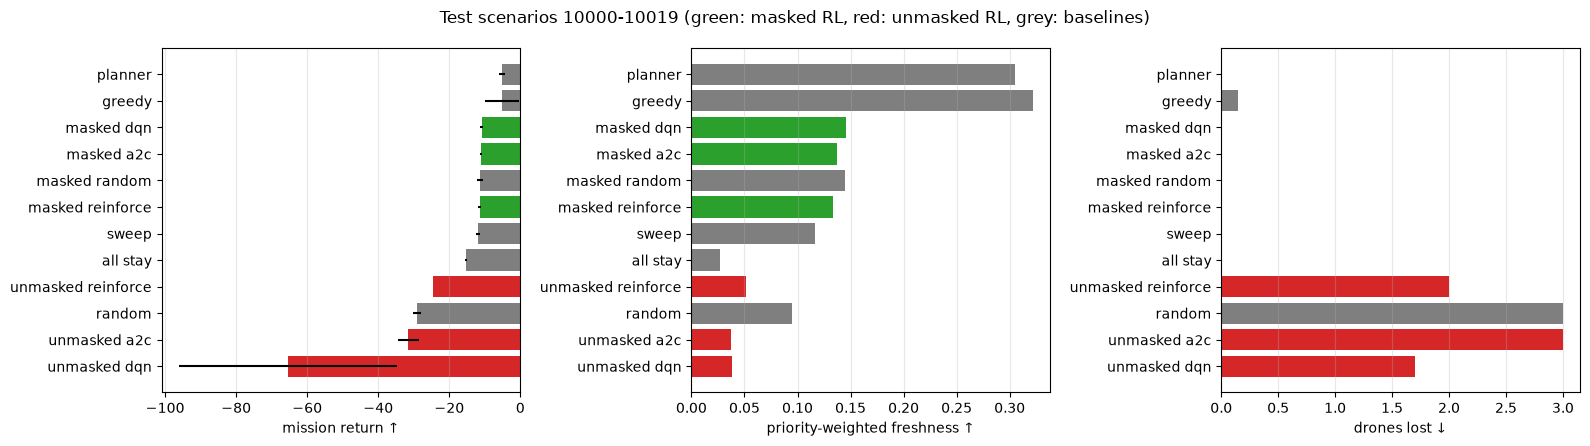

In [13]:
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, 'scripts/run_final_study.py', 'test', '--out', str(FINAL_OUT)], cwd=REPO, check=True)
summary = pd.read_csv(TEST_RESULTS / 'test_summary.csv').set_index('policy')
summary = summary.sort_values('return_mean', ascending=False)
columns = {'return_mean': 'return', 'return_sd': '± SD', 'weighted_freshness_mean': 'freshness',
           'overdue_fraction_mean': 'overdue', 'total_losses_mean': 'drones lost',
           'safe_returns_mean': 'safe returns', 'charge_completions_mean': 'charges',
           'energy_used_mean': 'energy', 'decision_ms_mean': 'decision ms'}
display(summary[list(columns)].rename(columns=columns))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colours = ['tab:green' if p.startswith('masked ') and p != 'masked random' else
           'tab:red' if p.startswith('unmasked') else 'tab:grey' for p in summary.index]
for ax, (metric, label) in zip(axes, [('return_mean', 'mission return ↑'),
                                       ('weighted_freshness_mean', 'priority-weighted freshness ↑'),
                                       ('total_losses_mean', 'drones lost ↓')]):
    ax.barh(summary.index, summary[metric], color=colours,
            xerr=summary['return_sd'] if metric == 'return_mean' else None)
    ax.set_xlabel(label); ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)
fig.suptitle('Test scenarios 10000-10019 (green: masked RL, red: unmasked RL, grey: baselines)')
plt.tight_layout(); plt.show()

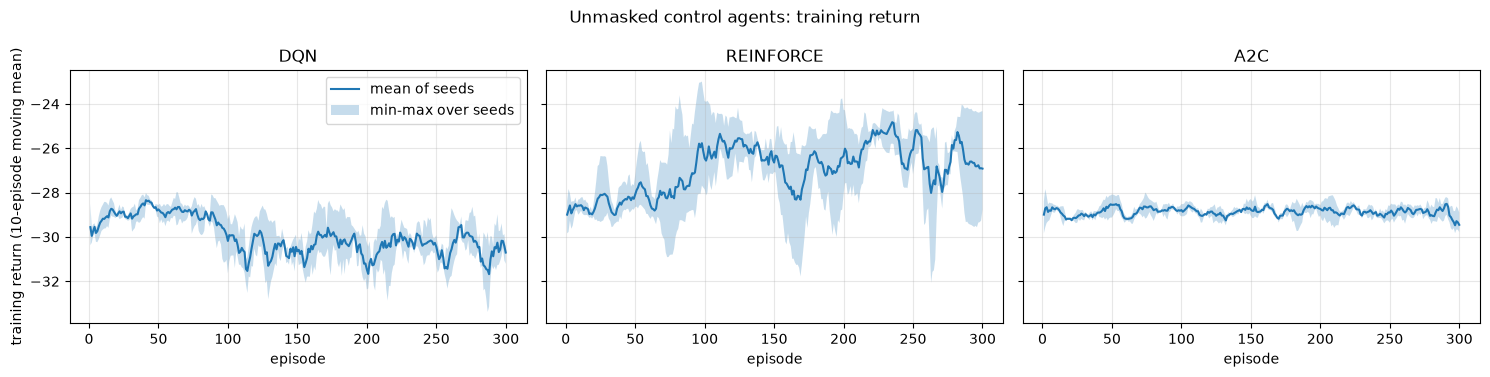

In [14]:
learning_curves((TEST_RESULTS if RUN_EXPERIMENTS else RESULTS / 'test') / 'unmasked', 'Unmasked control agents: training return')

## 10. Sensitivity: when does coordination matter?
**Author: _(name)_**

The proposal asked when coordination matters. We vary one resource or fire parameter at a
time, retrain the best masked agent (one seed) in each condition, and evaluate it with the
baselines on the 20 test scenarios.

policy,all stay,greedy,masked dqn,masked random,planner,random,sweep
condition,,,,,,,
default,-15.37,-5.27,-10.91,-11.37,-5.20,-29.04,-11.89
battery_capacity=120.0,-15.37,-4.34,-12.12,-10.75,-5.08,-27.56,-11.95
battery_capacity=60.0,-15.37,-4.63,-10.50,-11.09,-5.24,-29.75,-11.85
recharge_rate=3.0,-15.37,-6.49,-11.60,-11.60,-6.59,-29.05,-12.07
recharge_rate=8.0,-15.37,-4.82,-10.37,-10.94,-4.40,-29.02,-11.76
spread_probability=0.02,-15.40,-5.70,-10.69,-11.57,-5.36,-29.08,-11.93
spread_probability=0.08,-15.39,-6.50,-11.11,-11.58,-5.18,-28.94,-11.87


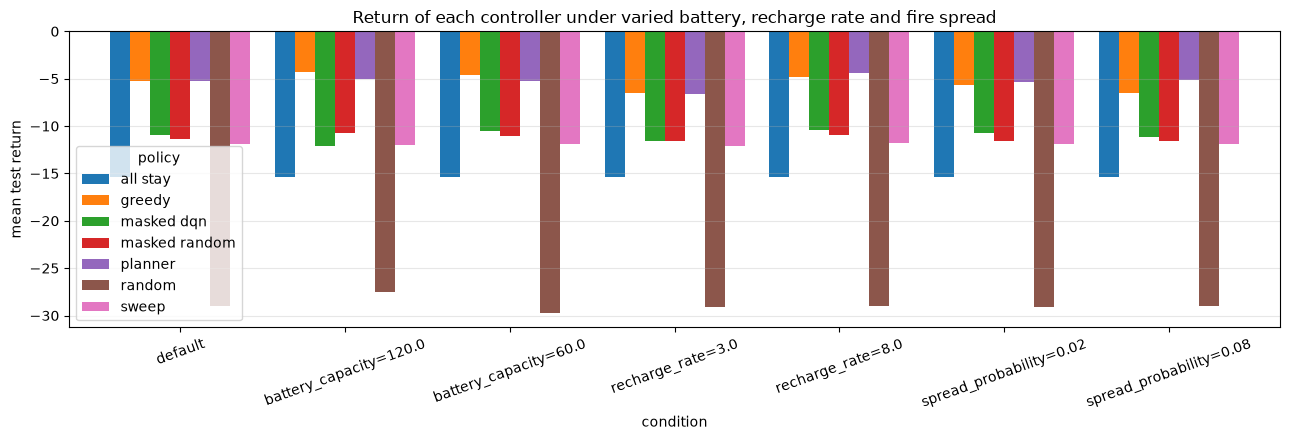

In [15]:
SENSITIVITY_AGENT = 'dqn'   # best masked agent on validation
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, 'scripts/run_final_study.py', 'sensitivity', '--seeds', '0',
                    '--algorithm', SENSITIVITY_AGENT, '--out', str(FINAL_OUT)], cwd=REPO, check=True)
sens = pd.read_csv(SENSITIVITY_RESULTS / 'sensitivity_summary.csv')
table = sens.pivot(index='condition', columns='policy', values='return_mean')
order = ['default'] + [c for c in table.index if c != 'default']
display(table.loc[order].round(2))
ax = table.loc[order].plot(kind='bar', figsize=(13, 4.5), width=0.85)
ax.set_ylabel('mean test return'); ax.grid(axis='y', alpha=0.3)
ax.set_title('Return of each controller under varied battery, recharge rate and fire spread')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 11. Critical review
**Author: _(name)_**

_This section is filled in from the results above; see the analysis cell output and the
report for the full discussion._

In [16]:
if RUN_EXPERIMENTS:
    display(Markdown('**Current run:** use these results for the critical review.'))
    display(summary[['return_mean', 'return_sd', 'weighted_freshness_mean', 'total_losses_mean']])
else:
    print((RESULTS / 'FINDINGS.md').read_text())


# Findings (5 Oct 2026 study)

## 1. Has the agent solved the problem?

Partly. **Masking solved safety but not coordination.**

On the 20 test scenarios, every masked agent kept the whole fleet alive in every mission
(0 losses). Their returns are -10.9 (DQN), -11.2 (A2C) and -11.5 (REINFORCE). The unmasked
agents trained the same way scored -24.6 to -65.4 and lost 1.7 to 3 drones per mission,
which is no better than random play (-29.0).

The masked agents are still far behind the planning baselines: greedy (-5.3), the
rolling-horizon planner (-5.2) and even sweep (-11.9) are close to or better than them.
They are about the same as **masked random (-11.4)**. So most of the improvement comes
from the mask, and the learned part adds little.

## 2. Why the learned part adds little

- **Tiny per-step signal.** Across feasible actions, the best and worst immediate reward
  differ by only 0.019 on average, and the best and second-best by 0.0017. Under masked
  random play, the mission return